## 1. Imports and paths

In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.api.types import is_numeric_dtype
import seaborn as sns

PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)

Set consistent theme for plots

In [4]:
sns.set_theme(style="whitegrid", context="paper", palette="husl")

In [5]:
PROJECT_ROOT = Path.cwd()
TRAIN_PATH = PROJECT_ROOT / "train.csv"
TEST_PATH = PROJECT_ROOT / "test.csv"

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/apple/Documents/modules/CS5228/cs-5228-2610-project


## 2. Load the main data

Load train and test files, and use statistics and visualization for the very first analysis of data. There are no missing values in the data as seen on the Kaggle data summary.


In [6]:
train = pd.read_csv(TRAIN_PATH, dtype={"BLOCK": "string"})
test = pd.read_csv(TEST_PATH, dtype={"BLOCK": "string"})

print(f"Train shape: {train.shape}")
print(f"Test shape:  {test.shape}")
print("\nMain columns:", list(train.columns))

Train shape: (150000, 11)
Test shape:  (50000, 10)

Main columns: ['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE', 'FEE', 'MONTHLY_RENT']


In [7]:
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RENT_APPROVAL_DATE,150000,51,2021-03,3705,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TOWN,150000,26,jurong west,10482,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BLOCK,150000,2720,2,921,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STREET,150000,1146,ang mo kio avenue 3,1590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLAT_TYPE,150000,11,4-room,40688,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLAT_MODEL,150000,20,improved,44008,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLOOR_AREA_SQM,150000.0,NaN,NaN,NaN,93.338847,24.271768,31.0,68.0,92.0,110.0,215.0
FURNISHED,150000,1,yes,150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LEASE_COMMENCE_DATE,150000.0,NaN,NaN,NaN,1990.907473,12.64154,1966.0,1981.0,1988.0,2001.0,2022.0
FEE,150000.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 2.0 Assess data quality
Check if the overall train and test data contains any missing values or duplicates. Also note the data types of each column to get an idea of numerical and categorical values. 

In [8]:
def data_quality(df, name):
    report = pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_percentage": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique(dropna=False),
    })

    print(f"===== {name} =====")
    print(f"Rows: {len(df):,}")
    print(f"Columns: {df.shape[1]}")
    print(f"Duplicate rows: {df.duplicated().sum():,}")
    print(f"Completely empty rows: {df.isna().all(axis=1).sum():,}")
    print()

    display(report)


data_quality(train, "Training data")
data_quality(test, "Test data")

===== Training data =====
Rows: 150,000
Columns: 11
Duplicate rows: 425
Completely empty rows: 0



,data_type,missing_count,missing_percentage,unique_values
RENT_APPROVAL_DATE,str,0,0.0,51
TOWN,str,0,0.0,26
BLOCK,string,0,0.0,2720
STREET,str,0,0.0,1146
FLAT_TYPE,str,0,0.0,11
FLAT_MODEL,str,0,0.0,20
FLOOR_AREA_SQM,float64,0,0.0,156
FURNISHED,str,0,0.0,1
LEASE_COMMENCE_DATE,int64,0,0.0,57
FEE,float64,0,0.0,1


===== Test data =====
Rows: 50,000
Columns: 10
Duplicate rows: 5,508
Completely empty rows: 0



,data_type,missing_count,missing_percentage,unique_values
RENT_APPROVAL_DATE,str,0,0.0,17
TOWN,str,0,0.0,26
BLOCK,string,0,0.0,2660
STREET,str,0,0.0,1129
FLAT_TYPE,str,0,0.0,6
FLAT_MODEL,str,0,0.0,19
FLOOR_AREA_SQM,float64,0,0.0,148
FURNISHED,str,0,0.0,1
LEASE_COMMENCE_DATE,int64,0,0.0,57
FEE,float64,0,0.0,1


In [9]:
import pandas as pd
import numpy as np

categorical_cols = [
    "TOWN",
    "BLOCK",
    "STREET",
    "FLAT_TYPE",
    "FLAT_MODEL",
    "FURNISHED",
]


def categorical_profile(df, columns, rare_threshold=0.01):
    rows = []

    for col in columns:
        s = df[col]
        non_null = s.dropna().astype("string")
        counts = non_null.value_counts()

        # Normalization used only to detect possible formatting inconsistencies
        normalized = (
            non_null
            .str.strip()
            .str.lower()
            .str.replace(r"[\s-]+", "-", regex=True)
        )

        raw_unique = non_null.nunique()
        normalized_unique = normalized.nunique()

        # Find examples where multiple raw values map to one normalized value
        variants = (
            pd.DataFrame({"raw": non_null, "normalized": normalized})
            .groupby("normalized")["raw"]
            .unique()
        )

        variant_examples = [
            " / ".join(map(str, values[:3]))
            for values in variants
            if len(values) > 1
        ]

        rare_cutoff = max(1, int(len(non_null) * rare_threshold))
        rare_categories = (counts < rare_cutoff).sum()

        rows.append({
            "column": col,
            "n_unique": raw_unique,
            "missing": s.isna().sum(),
            "most_frequent": counts.index[0] if len(counts) else None,
            "most_frequent_count": counts.iloc[0] if len(counts) else 0,
            "normalization_needed": normalized_unique < raw_unique,
            "normalization_examples": "; ".join(variant_examples[:3]),
        })

    return pd.DataFrame(rows)


categorical_summary = categorical_profile(train, categorical_cols)
display(categorical_summary)

,column,n_unique,missing,most_frequent,most_frequent_count,normalization_needed,normalization_examples
0,TOWN,26,0,jurong west,10482,False,
1,BLOCK,2720,0,2,921,False,
2,STREET,1146,0,ang mo kio avenue 3,1590,True,admiralty drive / Admiralty Drive; Admiralty L...
3,FLAT_TYPE,11,0,4-room,40688,True,1 room / 1-room; 2 room / 2-room; 3 room / 3-room
4,FLAT_MODEL,20,0,improved,44008,False,
5,FURNISHED,1,0,yes,150000,False,


### 2.1 Understanding categorical features

1. TOWN: The town of the sold HDB flat (e.g., "Bishan", "Queenstown", "Clementi"). 

    From the frequency count, we can see category imbalance: for example, bukit timah is under-represented whereas jurong west occurs many times. We use this information later to assess performance on rare catrgories.

    From the plots, most of the towns have rental options ranging from cheap to expensive, with some outliers on both the sides.

In [10]:
town = train["TOWN"]
town.value_counts()

TOWN
jurong west        10482
tampines            9942
sengkang            9773
bedok               8907
ang mo kio          8283
bukit merah         8270
yishun              7913
woodlands           7577
hougang             7115
punggol             6668
queenstown          6115
toa payoh           5988
kallang/whampoa     5689
bukit batok         5605
clementi            5429
choa chu kang       5300
geylang             4504
pasir ris           4089
jurong east         4024
bukit panjang       3717
sembawang           3553
serangoon           3398
bishan              3306
central             2278
marine parade       1637
bukit timah          438
Name: count, dtype: int64

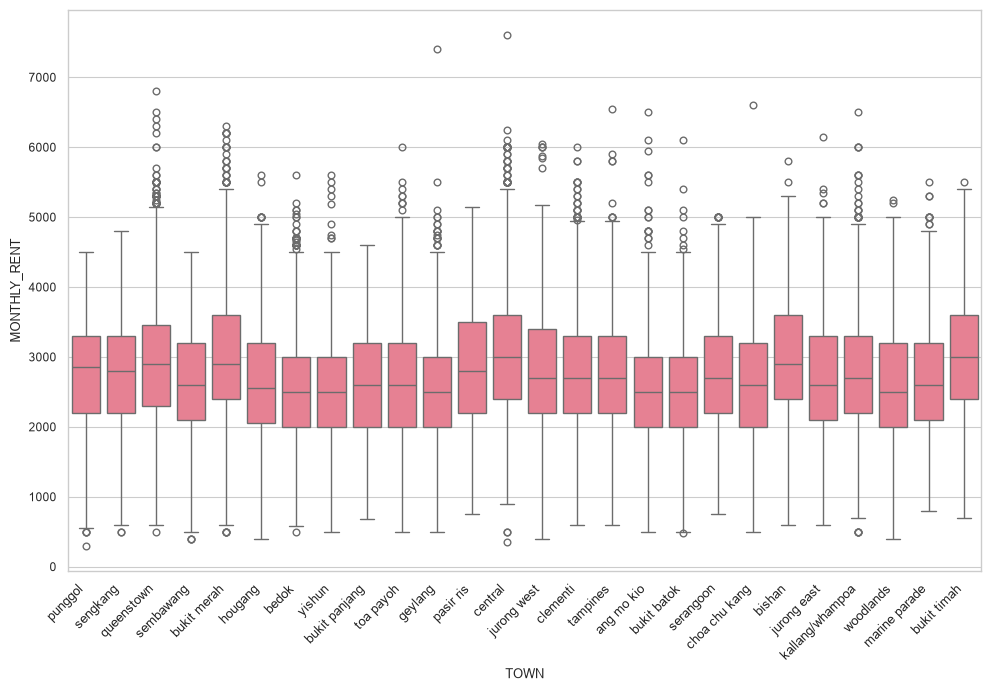

In [11]:
plt.figure(figsize=(10, 7))
sns.boxplot(data=train, x="TOWN", y="MONTHLY_RENT")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_rent_by_town.png", dpi=300, bbox_inches="tight")

2. BLOCK: block number of the flat (e.g., "300", "306A", "254"). This, by itself, is intuitively a weak indicator of rent. It has many unique values, but not much use on its own. It is not possible to plot this as a count plot or box-scatter plot due to high cardinality. NOTE: We can consider combining this with another feature in the final model.

3. STREET: Street name of block containing the flat (e.g., "ubi avenue 1", "woodlands drive 14"). This also contains many unique values, so difficult to plot. It can be a good indicator combined with town and block. Also, it needs normalization before we use it for predictions.

4. FLAT_TYPE: type of flat (e.g., "2 room", "3 room", "4-room"). This should be related to the size of the flat (FLOOR_AREA_SQM), so we can later plot and find any outliers/anomalies. Pre-processing: Normalize the categories so that '4 room' and '4-room' is the same category.

    1-room, 2-room and executive flats, are very less in number as compared to others. We address this imbalance while analysing our model errors.

    As expected, rent increases from 1-room flats to 5-room and then executive flats, on the average. There are also many expensive flats (may not be outliers) in the 3, 4, 5 room flats.

In [12]:
train["FLAT_TYPE"] = (
    train["FLAT_TYPE"].astype("string").str.lower()
    .str.replace(r"[\s-]+", "-", regex=True).str.strip()
)

train["FLAT_TYPE"].value_counts()

FLAT_TYPE
4-room       54079
3-room       49024
5-room       35523
executive     8234
2-room        3098
1-room          42
Name: count, dtype: Int64

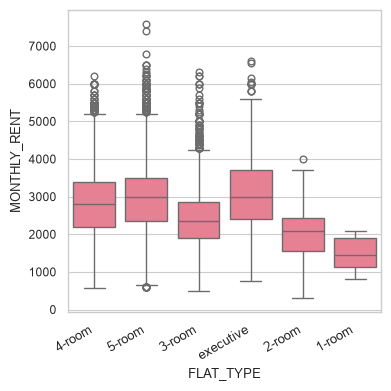

In [13]:
plt.figure(figsize=(4, 4))
sns.boxplot(data=train, x="FLAT_TYPE", y="MONTHLY_RENT")
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_rent_by_flat_type.png", dpi=300, bbox_inches="tight")

5. FLAT_MODEL - model of the flat (e.g., "model a", "dbss", ''executive"). This contains 20 unique values and might be a strong predictor of the rent.

    As observed in other categorical features, this one also has a large category imbalance with some categories with over 10,000 values, and some under 300. We can address this later by using some domain knowledge.

    From the plots, we can see that this might be a strong indicator.

In [14]:
flat_model = train["FLAT_MODEL"]
flat_model.value_counts()

FLAT_MODEL
improved                  44008
model a                   42745
new generation            27380
premium apartment         12312
simplified                 6794
standard                   5903
apartment                  4724
maisonette                 2346
model a2                   1553
dbss                       1090
type s1                     299
2 room                      224
adjoined flat               218
type s2                     160
model a maisonette          140
premium apartment loft       51
premium maisonette           21
terrace                      19
3gen                         12
improved maisonette           1
Name: count, dtype: int64

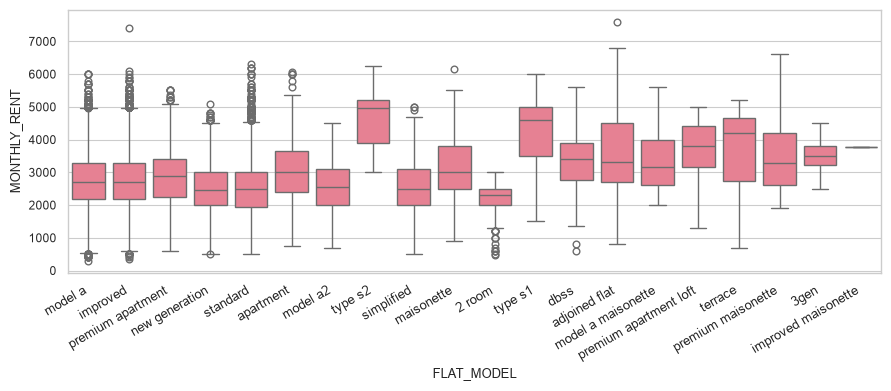

In [15]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=train, x="FLAT_MODEL", y="MONTHLY_RENT")
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_rent_by_flat_model.png", dpi=300, bbox_inches="tight")

6. FURNISHED: Whether the flat is furnished or not. NOTE: All flats are furnished, so we can safely remove this feature from prediction.

In [16]:
train["FURNISHED"].value_counts()

FURNISHED
yes    150000
Name: count, dtype: int64

### 2.2 Understanding Date features

1. Rent approval date: Year and Month when the rent was approved as string, e.g., "2021-01" representing January 2021. We plot the median target (monthly rent) values against approval dates, this gives us a generally increasing trend which indicates that this feature might be important.

    Later, we can pre-process these values as separate month and year or a combined "months elapsed since" numerical value.

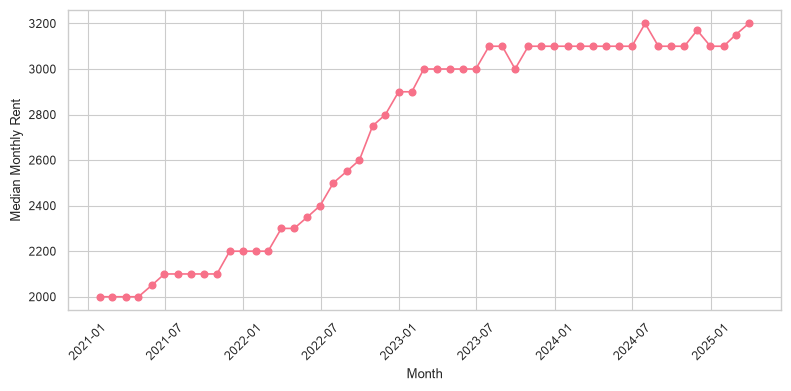

In [17]:
train["RENT_APPROVAL_DATE"] = pd.to_datetime(train["RENT_APPROVAL_DATE"], errors="coerce")

monthly_rent = (
    train.set_index("RENT_APPROVAL_DATE")["MONTHLY_RENT"]
         .resample("ME")
         .median()
)

plt.figure(figsize=(8, 4))
plt.plot(monthly_rent.index, monthly_rent.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Median Monthly Rent")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_rent_over_time.png", dpi=300, bbox_inches="tight")

2. LEASE_COMMENCE_DATE: Year the lease for flat commenced (e.g., 1984, 1985, 1986). We plot the median target (monthly rent) values against 5-year bins of lease commencement date, this gives us a generally increasing trend which indicates that older flats may have lesser rent.

    We can directly use this feature as a numerical value, as it mentions year only.

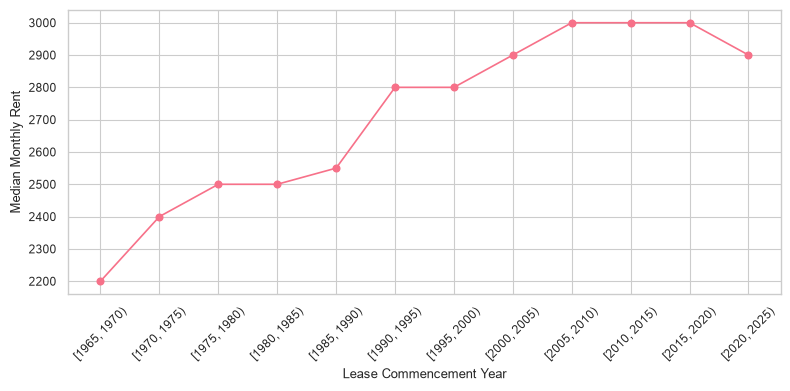

In [18]:
train["LEASE_COMMENCE_DATE"] = pd.to_numeric(
    train["LEASE_COMMENCE_DATE"],
    errors="coerce"
)

bin_size = 5  # change to 5 for five-year bins
min_year = int(train["LEASE_COMMENCE_DATE"].min())
max_year = int(train["LEASE_COMMENCE_DATE"].max())

bins = range((min_year // bin_size) * bin_size, ((max_year // bin_size) + 2) * bin_size, bin_size)
train["lease_year_bin"] = pd.cut(train["LEASE_COMMENCE_DATE"], bins=bins, right=False)
binned_rent = (train.groupby("lease_year_bin", observed=False)["MONTHLY_RENT"].median())

plt.figure(figsize=(8, 4))
plt.plot(
    binned_rent.index.astype(str),
    binned_rent.values,
    marker="o"
)
plt.xlabel("Lease Commencement Year")
plt.ylabel("Median Monthly Rent")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_rent_by_lease_year.png", dpi=300, bbox_inches="tight")

### 2.3 Understanding numerical features

7. FLOOR_AREA_SQM: Floor area in square meter (e.g., 104.0, 74.0, 136.0). As mentioned earlier, we plot this along with flat-type to see if it increases with number of rooms. 

    Observations: There are no obvious outliers, because the room size increases from 1-room to 2,3,4,5 and then executive, which is expected.

In [19]:
train["FLOOR_AREA_SQM"].describe()

count    150000.000000
mean         93.338847
std          24.271768
min          31.000000
25%          68.000000
50%          92.000000
75%         110.000000
max         215.000000
Name: FLOOR_AREA_SQM, dtype: float64

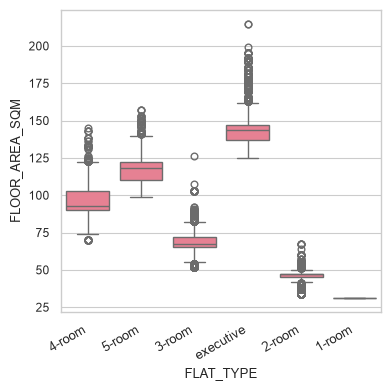

In [20]:
plt.figure(figsize=(4, 4))
sns.boxplot(data=train, x="FLAT_TYPE", y="FLOOR_AREA_SQM")
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "floor_area_by_flat_type.png", dpi=300, bbox_inches="tight")

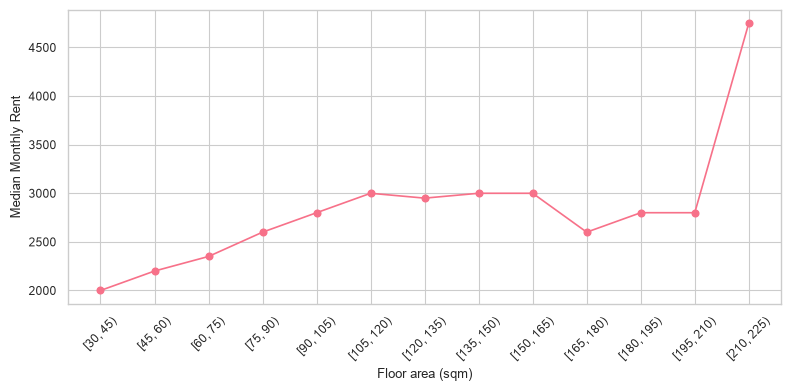

In [21]:
bin_size = 15  
min_year = int(train["FLOOR_AREA_SQM"].min())
max_year = int(train["FLOOR_AREA_SQM"].max())

bins = range((min_year // bin_size) * bin_size, ((max_year // bin_size) + 2) * bin_size, bin_size)
train["floor_area_bin"] = pd.cut(train["FLOOR_AREA_SQM"], bins=bins, right=False)
binned_area = (train.groupby("floor_area_bin", observed=False)["MONTHLY_RENT"].median())

plt.figure(figsize=(8, 4))
plt.plot(
    binned_area.index.astype(str),
    binned_area.values,
    marker="o"
)
plt.xlabel("Floor area (sqm)")
plt.ylabel("Median Monthly Rent")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_rent_by_floor_area.png", dpi=300, bbox_inches="tight")

2. FEE: additional upfront fee of rental agreement (e.g., 200, 300, 400). Always 0 for both train and test data, we can safely remove it.

In [22]:
train["FEE"].describe()

count    150000.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: FEE, dtype: float64

3. MONTHLY_RENT: Rental rate SGD (e.g., 2350, 4000, 3200): TARGET value

In [23]:
train["MONTHLY_RENT"].describe()

count    150000.000000
mean       2719.036893
std         749.731096
min         300.000000
25%        2100.000000
50%        2700.000000
75%        3200.000000
max        7600.000000
Name: MONTHLY_RENT, dtype: float64